In [1]:
import pandas as pd
df = pd.read_csv('data/Telco-Customer-Churn.csv')
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

In [2]:
from sklearn.model_selection import train_test_split
y = (df['Churn'] == 'Yes').astype(int)
X = df.drop(columns=['Churn', 'customerID'])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [3]:
print(X.shape)
print(X_train.shape, X_test.shape)
print(f'Churn train: {y_train.mean():.3f}')
print(f'Churn test: {y_test.mean():.3f}')

(7043, 19)
(5634, 19) (1409, 19)
Churn train: 0.265
Churn test: 0.265


In [4]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_cols = ['tenure','MonthlyCharges','TotalCharges']
categorical_cols = X_train.select_dtypes(include=['object','string']).columns.tolist()

numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='constant',fill_value=0)),
    ('scaler',StandardScaler()),
])
categorical_transformer = OneHotEncoder(handle_unknown='ignore')

preprocessor = ColumnTransformer(
    transformers=[
       ('num', numeric_transformer,numeric_cols),
       ('cat',categorical_transformer,categorical_cols),
    ],
    remainder='passthrough',
)
X_train_prep = preprocessor.fit_transform(X_train)
print(X_train_prep.shape)

(5634, 45)


In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate

logreg_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(max_iter=1000, random_state=42)),
])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    'roc_auc':'roc_auc',
    'recall':'recall',
    'precision':'precision',
    'pr_auc':'average_precision',
}
results = cross_validate(logreg_pipeline, X_train, y_train, cv=cv, scoring=scoring)
for name in scoring:
    scores = results[f'test_{name}']
    print(f'{name}: {scores.mean():.3f} +/- {scores.std():.3f}')

roc_auc: 0.846 +/- 0.013
recall: 0.544 +/- 0.041
precision: 0.654 +/- 0.027
pr_auc: 0.662 +/- 0.019


In [6]:
logreg_balanced_pipeline = Pipeline([
    ('preprocessor',preprocessor),
    ('model', LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced'))
])

In [7]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
smote_pipeline = ImbPipeline([
    ('preprocessor',preprocessor),
    ('smote',SMOTE(random_state=42)),
    ('model',LogisticRegression(max_iter=1000, random_state=42)),
])

In [8]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

neg, pos = (y_train == 0).sum(), (y_train == 1).sum()

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        max_depth=8,
        min_samples_leaf=10,
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
    )),
])

xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBClassifier(
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        n_estimators=300,
        scale_pos_weight=neg / pos,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1,
    )),
])

In [9]:
models = {
    'Baseline': logreg_pipeline,
    'Poids de classes': logreg_balanced_pipeline,
    'SMOTE': smote_pipeline,
    'Random Forest': rf_pipeline,
    'XGB': xgb_pipeline
}

for model_name, pipeline in models.items():
    results = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=scoring)
    print(model_name)
    for metric in scoring:
        scores = results[f'test_{metric}']
        print(f'{metric}: {scores.mean():.3f} +/- {scores.std():.3f}')

Baseline
roc_auc: 0.846 +/- 0.013
recall: 0.544 +/- 0.041
precision: 0.654 +/- 0.027
pr_auc: 0.662 +/- 0.019
Poids de classes
roc_auc: 0.846 +/- 0.012
recall: 0.801 +/- 0.038
precision: 0.517 +/- 0.019
pr_auc: 0.660 +/- 0.020
SMOTE
roc_auc: 0.845 +/- 0.013
recall: 0.789 +/- 0.040
precision: 0.526 +/- 0.018
pr_auc: 0.658 +/- 0.023
Random Forest
roc_auc: 0.848 +/- 0.010
recall: 0.797 +/- 0.023
precision: 0.528 +/- 0.018
pr_auc: 0.663 +/- 0.018
XGB
roc_auc: 0.846 +/- 0.012
recall: 0.791 +/- 0.022
precision: 0.525 +/- 0.013
pr_auc: 0.666 +/- 0.022


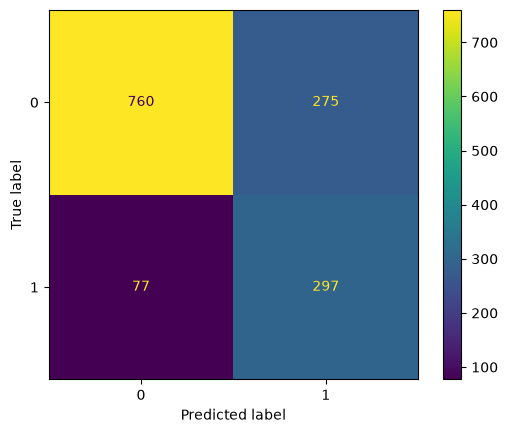

In [10]:
from sklearn.metrics import ConfusionMatrixDisplay

rf_pipeline.fit(X_train, y_train)
ConfusionMatrixDisplay.from_estimator(rf_pipeline, X_test, y_test)

In [11]:
from sklearn.metrics import average_precision_score, roc_auc_score

y_proba = rf_pipeline.predict_proba(X_test)[:, 1]

roc_auc = roc_auc_score(y_test, y_proba)
pr_auc = average_precision_score(y_test, y_proba)

print(f"ROC-AUC : {roc_auc:.3f}")
print(f"PR-AUC : {pr_auc:.3f}")

ROC-AUC : 0.843
PR-AUC : 0.652


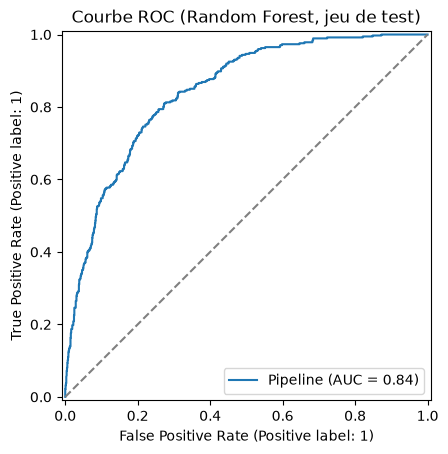

In [12]:
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_estimator(rf_pipeline, X_test, y_test)
plt.plot([0, 1], [0, 1], linestyle="--", color="grey")
plt.title("Courbe ROC (Random Forest, jeu de test)")
plt.show()

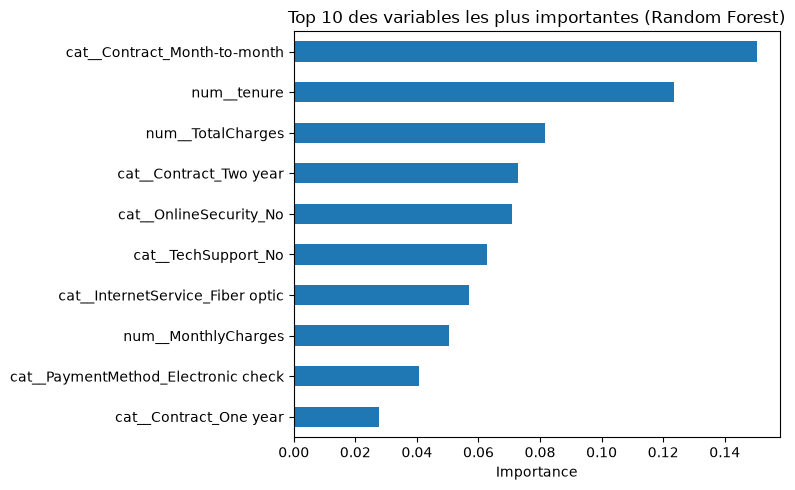

In [13]:
names = rf_pipeline["preprocessor"].get_feature_names_out()
importances = rf_pipeline["model"].feature_importances_
top10 = pd.Series(importances, index=names).nlargest(10)

plt.figure(figsize=(8, 5))
top10.sort_values().plot(kind="barh")
plt.title("Top 10 des variables les plus importantes (Random Forest)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()